In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("/Users/subhadyutirath/Documents/Manufacturing/data/raw/ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
def get_failure_type(row):

    if row["TWF"] == 1:
        return "Tool Wear Failure"

    elif row["HDF"] == 1:
        return "Heat Dissipation Failure"

    elif row["PWF"] == 1:
        return "Power Failure"

    elif row["OSF"] == 1:
        return "Overstrain Failure"

    elif row["RNF"] == 1:
        return "Random Failure"

    else:
        return "No Failure"


df["Failure_Type"] = df.apply(get_failure_type,axis=1)

In [3]:
df = df.drop(
    columns=[
        "UDI",
        "Product ID",
        "Machine failure",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
)

In [4]:
df["Temp_Diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]

In [5]:
df["Mechanical_Power"] = df["Rotational speed [rpm]"] * df["Torque [Nm]"]

In [6]:
df["Wear_Rate"] = df["Tool wear [min]"] / (df["Rotational speed [rpm]"] + 1)


In [7]:
df["Thermal_Stress"] = df["Process temperature [K]"] * df["Torque [Nm]"]


In [8]:
df["Wear_Torque"] = df["Tool wear [min]"] * df["Torque [Nm]"]

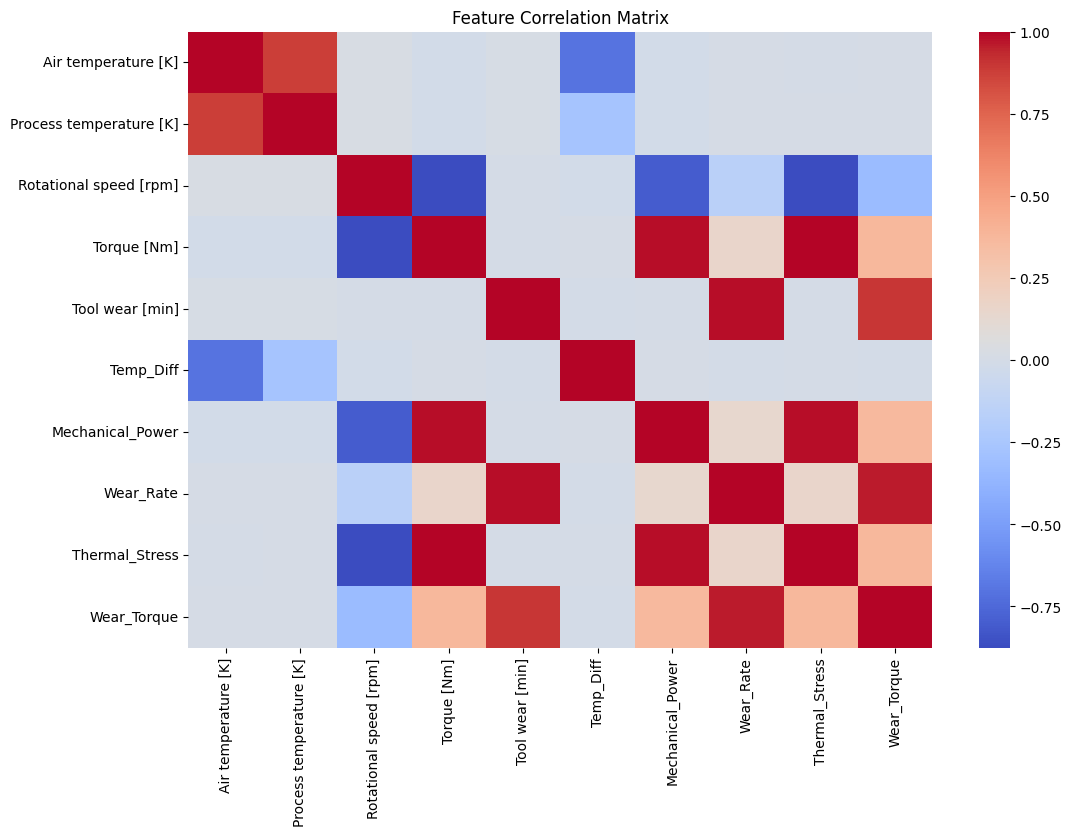

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(
        numeric_only=True
    ),
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [10]:
df.to_csv(
    "/Users/subhadyutirath/Documents/Manufacturing/data/processed/engineered_data.csv",
    index=False
)

print("Saved successfully")

Saved successfully


In [11]:
pd.read_csv("/Users/subhadyutirath/Documents/Manufacturing/data/processed/engineered_data.csv")

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Type,Temp_Diff,Mechanical_Power,Wear_Rate,Thermal_Stress,Wear_Torque
0,M,298.1,308.6,1551,42.8,0,No Failure,10.5,66382.8,0.000000,13208.08,0.0
1,L,298.2,308.7,1408,46.3,3,No Failure,10.5,65190.4,0.002129,14292.81,138.9
2,L,298.1,308.5,1498,49.4,5,No Failure,10.4,74001.2,0.003336,15239.90,247.0
3,L,298.2,308.6,1433,39.5,7,No Failure,10.4,56603.5,0.004881,12189.70,276.5
4,L,298.2,308.7,1408,40.0,9,No Failure,10.5,56320.0,0.006388,12348.00,360.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,No Failure,9.6,47318.0,0.008723,9097.80,413.0
9996,H,298.9,308.4,1632,31.8,17,No Failure,9.5,51897.6,0.010410,9807.12,540.6
9997,M,299.0,308.6,1645,33.4,22,No Failure,9.6,54943.0,0.013366,10307.24,734.8
9998,H,299.0,308.7,1408,48.5,25,No Failure,9.7,68288.0,0.017743,14971.95,1212.5


In [12]:
df.shape

(10000, 12)